<a href="https://colab.research.google.com/github/jaswanth424/MachineLearning/blob/main/Milestone_3_EDA_Banking_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Milestone 3 — Exploratory Data Analysis (EDA)
## Banking Fraud Detection and Risk Analytics

**Dataset:** `banking_transactions.csv`  
**Source:** [Kaggle — Banking Fraud Detection and Risk Analytics Dataset](https://www.kaggle.com/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/data)

### Objective
Explore, understand, and validate the dataset before machine-learning modeling. This notebook covers dataset overview, feature categorization, missingness and data quality, descriptive statistics, outliers, target analysis, relationships, and a preliminary preprocessing plan.

### Group 8
Isaac Irabor,
Jaswanth Kumar Reddy Chittem,
Md Faiaz,
Yokishan Krishnakumar

Submitted to : Prof. Elnaz Delpisheh

## 1. Setup and configuration

Import the libraries used for tabular analysis and visualizations.

In [84]:
# Core data analysis libraries
import warnings
import os
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown

# Reproducible display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 100

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset


In [85]:
FILE_PATH = '/content/banking_transactions.csv'

# Read the CSV. low_memory=False helps pandas infer mixed column types more consistently.
df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully.")
print(f"Dataset shape - Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")

Dataset loaded successfully.
Dataset shape - Rows: 10,000 | Columns: 20


## 2. Dataset overview

Inspect the dimensions, column names, data types, a sample of rows, and the likely target variable. The code checks common fraud-label names and asks for manual confirmation if none is found.

In [86]:
# Preview records and column names
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

# Dataset size and memory footprint
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

# File size
# Size in bytes
file_size_bytes = os.path.getsize(FILE_PATH)
# Size in Megabytes (MB)
file_size_mb = file_size_bytes / (1024 * 1024)
print(f"File Size: {file_size_mb:.2f} MB")
print("------------------------")

# Data types and non-null counts
display(df.info())
display(df.dtypes.rename("dtype").to_frame())

,transaction_id,transaction_amount,login_attempts,device_risk_score,transfer_frequency,anomaly_score,account_age_days,transaction_time_hour,failed_transactions_last_30d,avg_monthly_balance,daily_transaction_count,geo_distance_km,session_duration_minutes,transaction_velocity_score,payment_channel,authentication_type,card_present_flag,international_transaction_flag,suspicious_ip_flag,fraud_flag
0,1000001,17829.01,4,12.0,13,0.37,2354,22,25,112760.07,63,3189,92,71.8,POS Terminal,OTP,1,1,1,False
1,1000002,16401.83,1,34.3,17,0.26,3181,17,15,118899.52,83,839,63,11.8,Web Banking,Biometric,0,0,1,False
2,1000003,9678.29,8,67.8,39,0.15,1390,3,2,408168.98,9,3938,80,35.7,ATM,OTP,1,0,1,False
3,1000004,19013.38,5,17.8,42,0.55,3716,16,6,80771.69,78,11111,11,74.8,Mobile App,OTP,1,1,0,False
4,1000005,13834.95,3,88.9,63,0.24,4694,16,10,382265.32,17,3171,87,0.0,Mobile App,OTP,1,0,0,False



Column names:
['transaction_id', 'transaction_amount', 'login_attempts', 'device_risk_score', 'transfer_frequency', 'anomaly_score', 'account_age_days', 'transaction_time_hour', 'failed_transactions_last_30d', 'avg_monthly_balance', 'daily_transaction_count', 'geo_distance_km', 'session_duration_minutes', 'transaction_velocity_score', 'payment_channel', 'authentication_type', 'card_present_flag', 'international_transaction_flag', 'suspicious_ip_flag', 'fraud_flag']
Shape: 10,000 rows × 20 columns
File Size: 0.98 MB
------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   transaction_id                  10000 non-null  int64  
 1   transaction_amount              10000 non-null  float64
 2   login_attempts                  10000 non-null  int64  
 3   device_risk_score               100

None

,dtype
transaction_id,int64
transaction_amount,float64
login_attempts,int64
device_risk_score,float64
transfer_frequency,int64
anomaly_score,float64
account_age_days,int64
transaction_time_hour,int64
failed_transactions_last_30d,int64
avg_monthly_balance,float64


## 3. Data types and feature categorization

Features are grouped into **numerical**, **categorical**, **temporal**, and **identifier** variables. The first pass uses pandas data types and column-name patterns; review the output because numeric codes and date strings can be misclassified by automatic rules.

In [87]:
# Name-based patterns for common identifier and temporal fields.
temporal_patterns = [
    "date", "time", "timestamp", "datetime", "created_at", "updated_at"
]

TARGET ='fraud_flag'

identifier_cols = []
temporal_cols = []
for col in df.columns:
    name = str(col).strip().lower()
    # A column name ending in or containing an ID token is a likely identifier.
    if (name in {"id", "transaction_id", "customer_id", "account_id", "user_id"}
        or name.endswith("_id") or name.startswith("id_")
        or any(p in name for p in ["uuid", "reference_no"])):
        identifier_cols.append(col)

    # Column names suggesting dates/times are temporal candidates.
    if any(pattern in name for pattern in temporal_patterns):
        temporal_cols.append(col)

# Attempt to parse temporal candidates; only convert columns when parsing succeeds reasonably often.
parsed_temporal_cols = []
for col in temporal_cols:
    parsed = pd.to_datetime(df[col], errors="coerce")
    non_missing_original = df[col].notna().sum()
    if non_missing_original > 0:
        parse_rate = parsed.notna().sum() / non_missing_original
        if parse_rate >= 0.70:
            df[col] = parsed
            parsed_temporal_cols.append(col)

# Exclude target and identifiers from general predictor categorization.
excluded_from_predictors = set(identifier_cols)

numerical_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in excluded_from_predictors
]
categorical_cols = [
    c for c in df.select_dtypes(include=["object", "category", "bool"]).columns
    if c not in excluded_from_predictors and c not in parsed_temporal_cols
]
temporal_cols = [
    c for c in df.columns
    if pd.api.types.is_datetime64_any_dtype(df[c])
]

# Print category lists for review.
print("Identifier candidates:", identifier_cols)
print("Temporal columns parsed as datetime:", temporal_cols)
print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)

# A compact feature inventory table
feature_inventory = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_percent": [round(df[c].isna().mean() * 100, 2) for c in df.columns],
})
def feature_group(col):
    if col in identifier_cols:
        return "Identifier candidate"
    if col in temporal_cols:
        return "Temporal"
    if col in numerical_cols:
        return "Numerical"
    if col in categorical_cols:
        return "Categorical"
    return "Review manually"

feature_inventory["feature_group"] = feature_inventory["column"].map(feature_group)
display(feature_inventory)

Identifier candidates: ['transaction_id']
Temporal columns parsed as datetime: ['transaction_time_hour']
Numerical features: ['transaction_amount', 'login_attempts', 'device_risk_score', 'transfer_frequency', 'anomaly_score', 'account_age_days', 'failed_transactions_last_30d', 'avg_monthly_balance', 'daily_transaction_count', 'geo_distance_km', 'session_duration_minutes', 'transaction_velocity_score', 'card_present_flag', 'international_transaction_flag', 'suspicious_ip_flag']
Categorical features: ['payment_channel', 'authentication_type', 'fraud_flag']


,column,dtype,missing_count,missing_percent,feature_group
0,transaction_id,int64,0,0.0,Identifier candidate
1,transaction_amount,float64,0,0.0,Numerical
2,login_attempts,int64,0,0.0,Numerical
3,device_risk_score,float64,0,0.0,Numerical
4,transfer_frequency,int64,0,0.0,Numerical
5,anomaly_score,float64,0,0.0,Numerical
6,account_age_days,int64,0,0.0,Numerical
7,transaction_time_hour,datetime64[ns],0,0.0,Temporal
8,failed_transactions_last_30d,int64,0,0.0,Numerical
9,avg_monthly_balance,float64,0,0.0,Numerical


## 4. Missing data and quality assessment

Quantify missing values, visualize missingness, inspect duplicates, and check for mixed or suspicious values. Missing-value treatment should depend on the feature meaning and the fraction/pattern of missingness, not on a single universal threshold.

In [88]:
# Missing values per column, sorted from most to least missing.
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0].round(2))

# Visualize missingness only when missing values exist.
missing_cols = missing_summary[missing_summary["missing_count"] > 0].index.tolist()
if missing_cols:
    plt.figure(figsize=(max(10, len(missing_cols) * 0.5), 5))
    sns.heatmap(df[missing_cols].isna().sample(min(len(df), 1000), random_state=RANDOM_STATE),
                cbar=False, yticklabels=False)
    plt.title("Missingness pattern (sample of up to 1,000 rows)")
    plt.xlabel("Columns with missing values")
    plt.tight_layout()
    plt.show()
else:
    print("No pandas-recognized missing values found.")

# Duplicate row checks
duplicate_rows = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_rows:,} ({duplicate_rows / max(len(df), 1) * 100:.2f}%)")

# Check duplicated values in identifier-like columns (if present).
for col in identifier_cols:
    duplicate_ids = int(df[col].duplicated().sum())
    print(f"Repeated values in {col!r}: {duplicate_ids:,}")

# Whitespace-only strings and leading/trailing whitespace in text columns.
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    whitespace_only = df[col].astype("string").str.strip().eq("").sum()
    padded = (df[col].notna() & (df[col].astype(str) != df[col].astype(str).str.strip())).sum()
    if whitespace_only or padded:
        print(f"{col}: whitespace-only={int(whitespace_only)}, padded strings={int(padded)}")

,missing_count,missing_percent


No pandas-recognized missing values found.
Exact duplicate rows: 0 (0.00%)
Repeated values in 'transaction_id': 0


### 4.1 Inspect unusual values and inconsistent formats

The next cell shows distinct values for low-cardinality columns and samples values for high-cardinality text fields. Use this to identify spelling variants, inconsistent labels, placeholder values, or unexpected formats.

In [89]:
# Low-cardinality columns are useful for checking label consistency.
for col in df.columns:
    nunique = df[col].nunique(dropna=True)
    if nunique <= 30:
        print(f"\n--- {col} (unique non-null values: {nunique}) ---")
        display(df[col].value_counts(dropna=False).head(35).to_frame("count"))
    elif df[col].dtype == "object":
        print(f"\n--- {col}: sample distinct values ---")
        display(df[col].dropna().astype(str).drop_duplicates().head(10).to_frame("sample"))


--- login_attempts (unique non-null values: 12) ---


,count
login_attempts,
9,909
3,898
2,878
5,849
11,840
1,834
7,823
4,813
8,805



--- transaction_time_hour (unique non-null values: 24) ---


,count
transaction_time_hour,
1970-01-01 00:00:00.000000003,444
1970-01-01 00:00:00.000000022,441
1970-01-01 00:00:00.000000011,441
1970-01-01 00:00:00.000000002,439
1970-01-01 00:00:00.000000008,438
1970-01-01 00:00:00.000000020,437
1970-01-01 00:00:00.000000017,426
1970-01-01 00:00:00.000000010,426
1970-01-01 00:00:00.000000019,423



--- failed_transactions_last_30d (unique non-null values: 26) ---


...

,count
international_transaction_flag,
0,5016
1,4984



--- suspicious_ip_flag (unique non-null values: 2) ---


,count
suspicious_ip_flag,
1,5005
0,4995



--- fraud_flag (unique non-null values: 2) ---


,count
fraud_flag,
False,8749
True,1251


## 5. Descriptive statistics

Numerical summaries show central tendency, dispersion, and distribution shape. Categorical frequency tables show dominant classes and rare categories.

In [90]:
# Numerical summary including quartiles and additional shape statistics.
numeric_for_summary = df.select_dtypes(include=np.number).columns.tolist()
if numeric_for_summary:
    numeric_summary = df[numeric_for_summary].describe().T
    numeric_summary["missing_count"] = df[numeric_for_summary].isna().sum()
    numeric_summary["skewness"] = df[numeric_for_summary].skew(numeric_only=True)
    numeric_summary["unique_values"] = df[numeric_for_summary].nunique()
    display(numeric_summary.round(3))
else:
    print("No numeric columns detected.")

# Categorical frequency counts (show top 20 categories per column).
for col in categorical_cols:
    print(f"\nFrequency counts — {col}")
    display(df[col].value_counts(dropna=False).head(20).to_frame("count"))

,count,mean,std,min,25%,50%,75%,max,missing_count,skewness,unique_values
transaction_id,10000.0,1005000.500,2886.896,1000001.00,1002500.750,1005000.500,1007500.250,1010000.00,0,0.000,10000
transaction_amount,10000.0,12412.754,7200.701,6.27,6174.025,12322.965,18619.650,24997.52,0,0.021,9981
login_attempts,10000.0,6.439,3.454,1.00,3.000,6.000,9.000,12.00,0,0.016,12
device_risk_score,10000.0,50.257,29.414,0.00,25.100,50.200,75.500,100.00,0,0.006,1001
transfer_frequency,10000.0,39.648,23.420,0.00,19.000,40.000,60.000,80.00,0,0.021,81
anomaly_score,10000.0,0.349,0.237,0.01,0.170,0.310,0.480,0.99,0,0.687,99
account_age_days,10000.0,2510.241,1436.335,6.00,1271.750,2511.000,3746.250,5000.00,0,0.000,4339
failed_transactions_last_30d,10000.0,12.438,7.533,0.00,6.000,13.000,19.000,25.00,0,-0.006,26
avg_monthly_balance,10000.0,249367.528,144580.007,104.16,122291.355,249799.800,373146.842,499968.25,0,0.000,9997
daily_transaction_count,10000.0,60.614,34.822,1.00,30.750,60.000,91.000,120.00,0,0.006,120



Frequency counts — payment_channel


,count
payment_channel,
Mobile App,4804
Web Banking,3247
POS Terminal,1172
ATM,777



Frequency counts — authentication_type


,count
authentication_type,
OTP,4214
Two-Factor Authentication,2384
Password Only,1817
Biometric,1585



Frequency counts — fraud_flag


,count
fraud_flag,
False,8749
True,1251


### 5.1 Numerical distributions

Histograms help reveal skewness, multiple peaks, and suspicious values. For readability, this section plots a limited number of numerical columns; adjust `MAX_PLOTS` if needed.

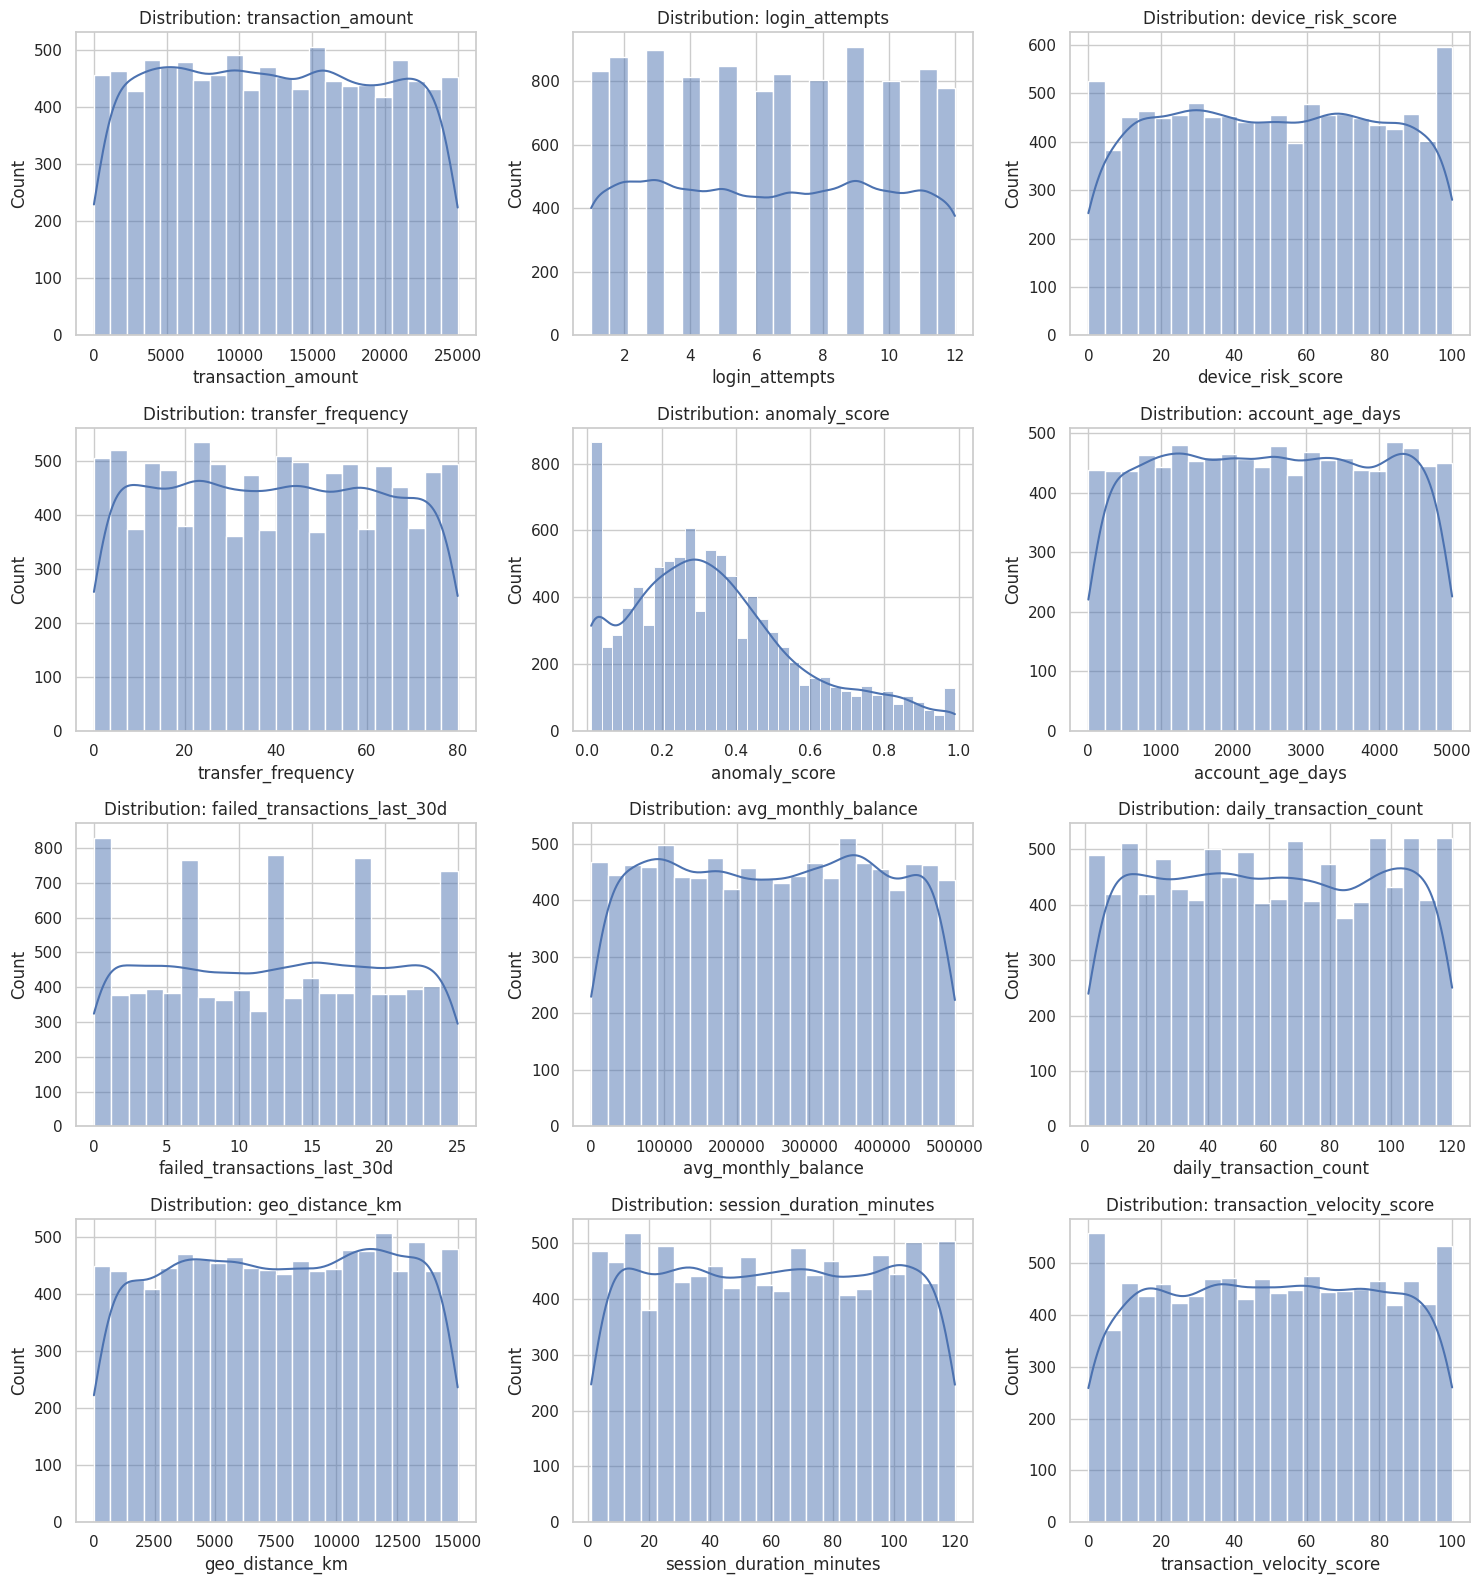

In [91]:
MAX_PLOTS = 12
plot_cols = numerical_cols[:MAX_PLOTS]

if plot_cols:
    ncols = 3
    nrows = int(np.ceil(len(plot_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, plot_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=ax)
        ax.set_title(f"Distribution: {col}")
        ax.set_xlabel(col)

    for ax in axes[len(plot_cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()
else:
    print("No numerical predictor columns to plot.")

## 6. Outliers and range checks

Use boxplots and the IQR rule to **flag** potential outliers. Outliers may be legitimate high-value transactions or useful fraud signals, so this notebook does not automatically remove or cap them. Confirm domain-valid ranges using the data dictionary.

,column,Q1,Q3,IQR,lower_IQR_bound,upper_IQR_bound,outlier_count,outlier_percent
4,anomaly_score,0.170,0.480,0.310,-0.295,0.945,162,1.62
1,login_attempts,3.000,9.000,6.000,-6.000,18.000,0,0.00
0,transaction_amount,6174.025,18619.650,12445.625,-12494.412,37288.087,0,0.00
2,device_risk_score,25.100,75.500,50.400,-50.500,151.100,0,0.00
3,transfer_frequency,19.000,60.000,41.000,-42.500,121.500,0,0.00
5,account_age_days,1271.750,3746.250,2474.500,-2440.000,7458.000,0,0.00
6,failed_transactions_last_30d,6.000,19.000,13.000,-13.500,38.500,0,0.00
7,avg_monthly_balance,122291.355,373146.842,250855.488,-253991.876,749430.074,0,0.00
8,daily_transaction_count,30.750,91.000,60.250,-59.625,181.375,0,0.00
9,geo_distance_km,3896.000,11376.250,7480.250,-7324.375,22596.625,0,0.00


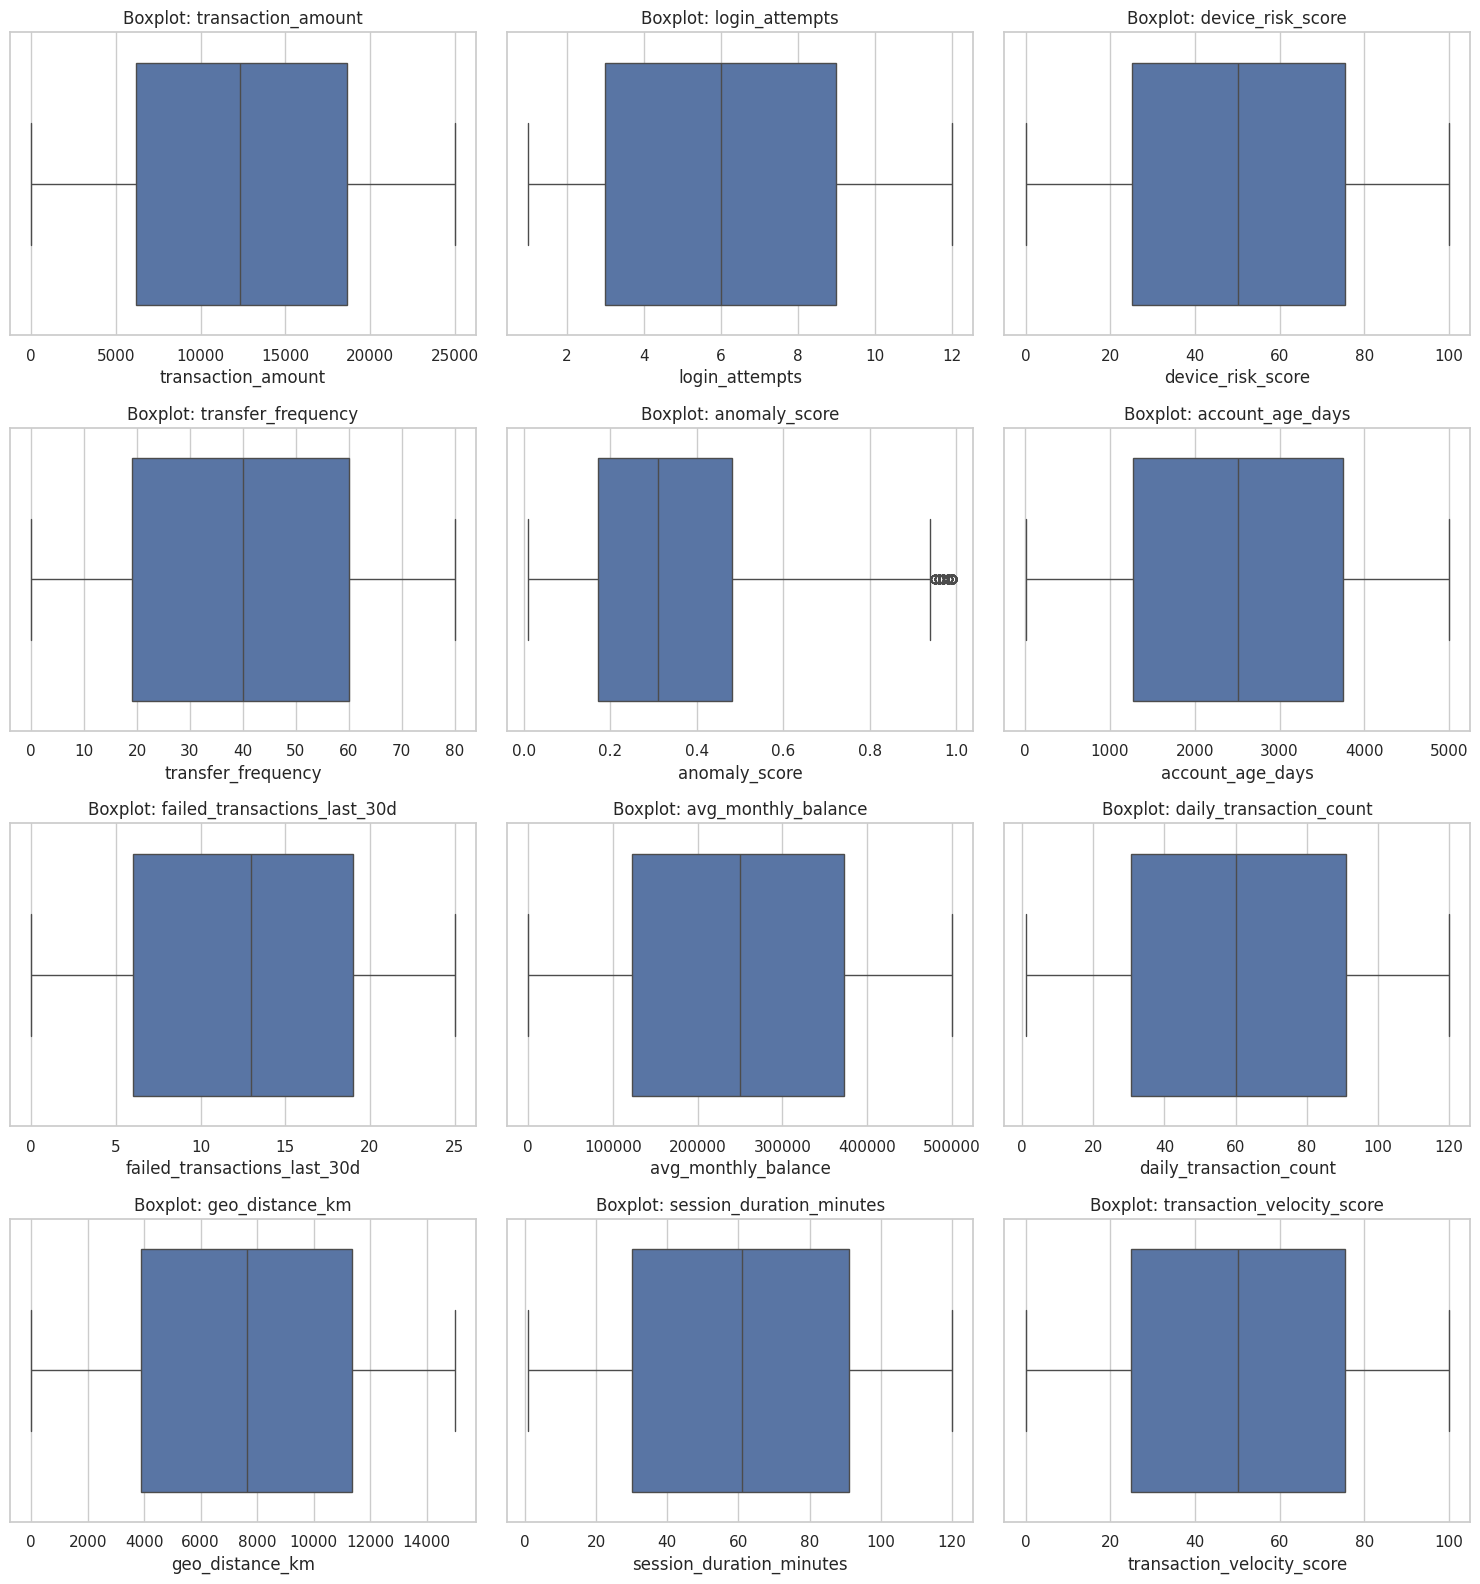

In [92]:
# IQR-based outlier counts for numeric predictors.
outlier_rows = []
for col in numerical_cols:
    series = df[col].dropna()
    if series.empty:
        continue
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({
        "column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_IQR_bound": lower,
        "upper_IQR_bound": upper,
        "outlier_count": count,
        "outlier_percent": count / len(series) * 100
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("outlier_percent", ascending=False)
display(outlier_summary.round(3))

# Boxplots for a subset of numerical columns.
box_cols = numerical_cols[:min(12, len(numerical_cols))]
if box_cols:
    ncols = 3
    nrows = int(np.ceil(len(box_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, box_cols):
        sns.boxplot(x=df[col], ax=ax)
        ax.set_title(f"Boxplot: {col}")
    for ax in axes[len(box_cols):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

# Example range checks: edit these after consulting the dataset's data dictionary.
# Set known valid ranges, e.g. {"customer_age": (18, 100), "transaction_amount": (0, None)}
KNOWN_RANGES = {}

for col, (min_allowed, max_allowed) in KNOWN_RANGES.items():
    if col not in df.columns:
        print(f"Range check skipped; column not found: {col}")
        continue
    values = pd.to_numeric(df[col], errors="coerce")
    invalid = pd.Series(False, index=df.index)
    if min_allowed is not None:
        invalid |= values < min_allowed
    if max_allowed is not None:
        invalid |= values > max_allowed
    print(f"{col}: {int(invalid.sum())} values outside configured range.")

## 7. Target variable exploration

Fraud detection is usually a binary classification problem. This section inspects the target distribution, class balance, and possible relationships between features and the target. If the target was not detected automatically, set `TARGET` manually in Section 2 and rerun the relevant cells.

Target value counts (including missing):


,count
fraud_flag,
False,8749
True,1251


,count,percent
fraud_flag,,
False,8749,87.49
True,1251,12.51


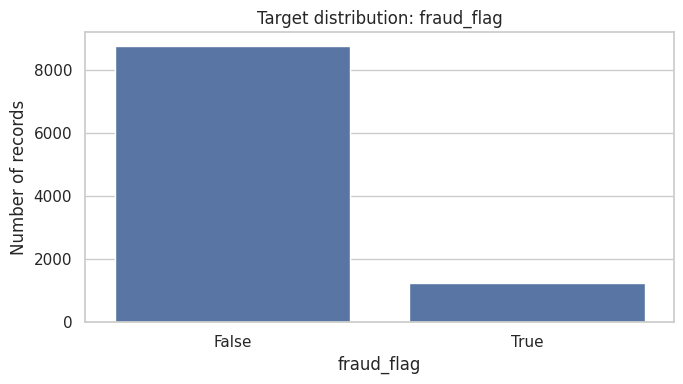

Class percentages:


,percent
fraud_flag,
False,87.49
True,12.51


Consider imbalance-aware evaluation later (e.g., precision, recall, PR-AUC),
rather than relying on accuracy alone.


In [93]:
if TARGET is None or TARGET not in df.columns:
    print("Target not configured. Set TARGET to the actual fraud-label column and rerun this section.")
else:
    print("Target value counts (including missing):")
    display(df[TARGET].value_counts(dropna=False).to_frame("count"))

    target_counts = df[TARGET].value_counts(dropna=False)
    target_percent = df[TARGET].value_counts(normalize=True, dropna=False) * 100
    target_summary = pd.concat(
        [target_counts.rename("count"), target_percent.rename("percent")], axis=1
    )
    display(target_summary.round(3))

    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
    plt.title(f"Target distribution: {TARGET}")
    plt.xlabel(TARGET)
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

    # For binary labels, report the minority-class proportion.
    non_null_target = df[TARGET].dropna()
    if non_null_target.nunique() == 2:
        class_pct = non_null_target.value_counts(normalize=True) * 100
        print("Class percentages:")
        display(class_pct.rename("percent").to_frame())
        print("Consider imbalance-aware evaluation later (e.g., precision, recall, PR-AUC),")
        print("rather than relying on accuracy alone.")

### 7.1 Feature relationships with the target

For numerical features, compare distributions by target class and calculate simple correlations where meaningful. For categorical features, compare fraud rates across categories. These are exploratory associations, not proof of causation, and rare categories can produce unstable rates.

Numerical features ranked by absolute correlation with target:


,correlation_with_target
anomaly_score,0.6748
geo_distance_km,-0.0178
suspicious_ip_flag,0.0096
transaction_velocity_score,0.0096
daily_transaction_count,-0.0093
failed_transactions_last_30d,-0.0075
international_transaction_flag,-0.0057
transaction_amount,0.0054
account_age_days,-0.0052
session_duration_minutes,0.0046


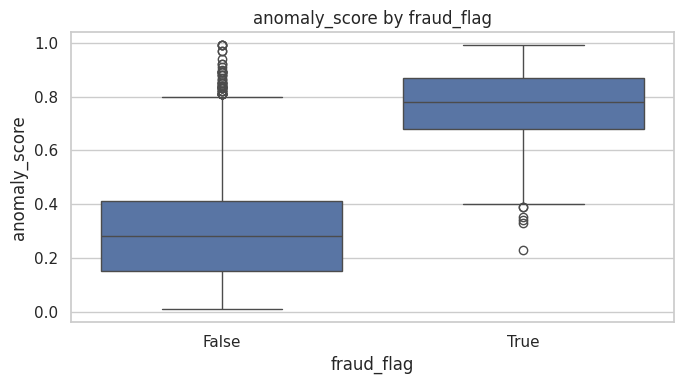

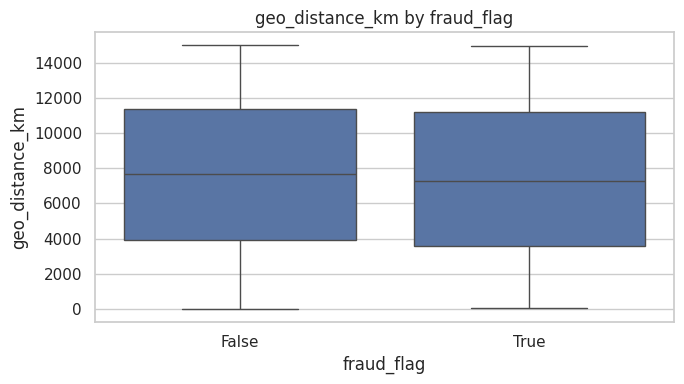

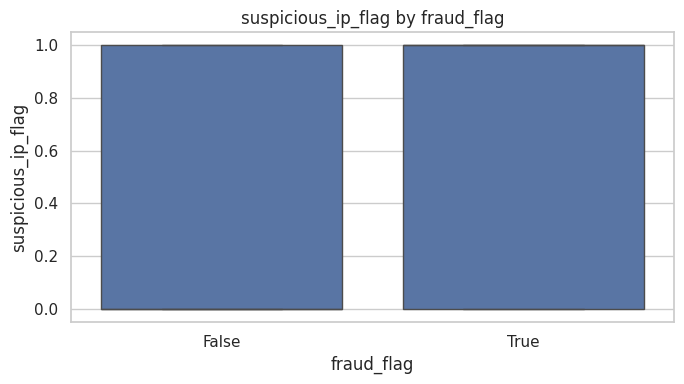

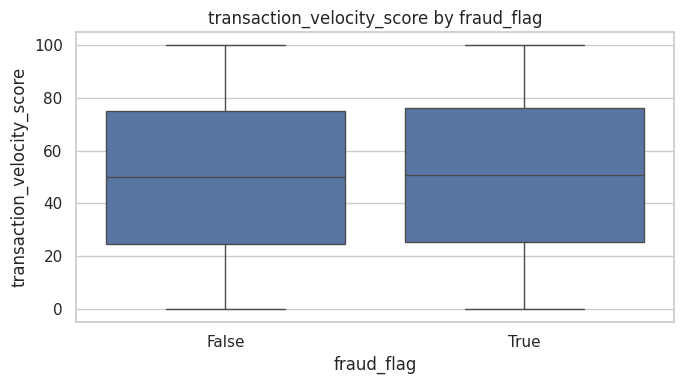

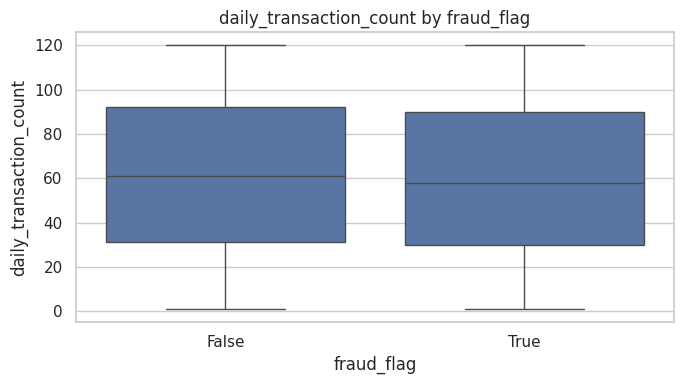

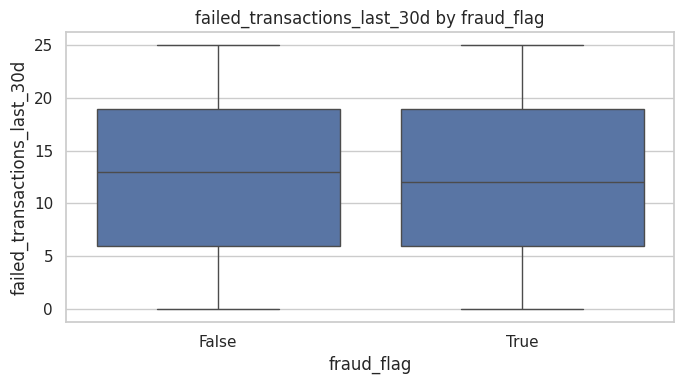

,Mean fraud_flag,records
payment_channel,,
ATM,0.129987,777
Mobile App,0.128226,4804
Web Banking,0.123191,3247
POS Terminal,0.114334,1172


,Mean fraud_flag,records
authentication_type,,
OTP,0.130755,4214
Password Only,0.127683,1817
Biometric,0.120505,1585
Two-Factor Authentication,0.116191,2384


,Mean fraud_flag,records
fraud_flag,,
True,1.0,1251
False,0.0,8749


In [94]:
if TARGET is not None and TARGET in df.columns:
    # Numeric target-feature correlations are meaningful only if the target can be represented numerically.
    target_numeric = pd.to_numeric(df[TARGET], errors="coerce")
    if target_numeric.notna().sum() > 0:
        numeric_features_for_corr = [
            c for c in numerical_cols if c != TARGET and df[c].nunique(dropna=True) > 1
        ]
        corr_df = df[numeric_features_for_corr].copy()
        corr_df["_target_numeric"] = target_numeric
        correlations = corr_df.corr(numeric_only=True)["_target_numeric"].drop("_target_numeric")
        correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
        print("Numerical features ranked by absolute correlation with target:")
        display(correlations.to_frame("correlation_with_target").head(20).round(4))

        if numeric_features_for_corr:
            top_corr_features = correlations.abs().head(min(6, len(correlations))).index.tolist()
            for col in top_corr_features:
                plt.figure(figsize=(7, 4))
                sns.boxplot(data=df, x=TARGET, y=col)
                plt.title(f"{col} by {TARGET}")
                plt.tight_layout()
                plt.show()

    # Fraud rate by category for a small number of categorical features.
    if df[TARGET].nunique(dropna=True) <= 10:
        for col in categorical_cols[:8]:
            grouped = df.groupby(col, dropna=False)[TARGET].agg(["mean", "count"])
            grouped = grouped.rename(columns={"mean": "target_mean", "count": "records"})
            grouped = grouped[grouped["records"] >= max(5, int(0.005 * len(df)))]
            if not grouped.empty:
                display(grouped.sort_values("target_mean", ascending=False).head(15)
                        .rename(columns={"target_mean": f"Mean {TARGET}"}))
else:
    print("Target not configured; skip target relationship analysis.")

### 7.2 Correlation heatmap

A correlation matrix can highlight redundant numerical features and possible linear relationships. Correlation alone does not establish predictive usefulness, especially for non-linear patterns or imbalanced targets.

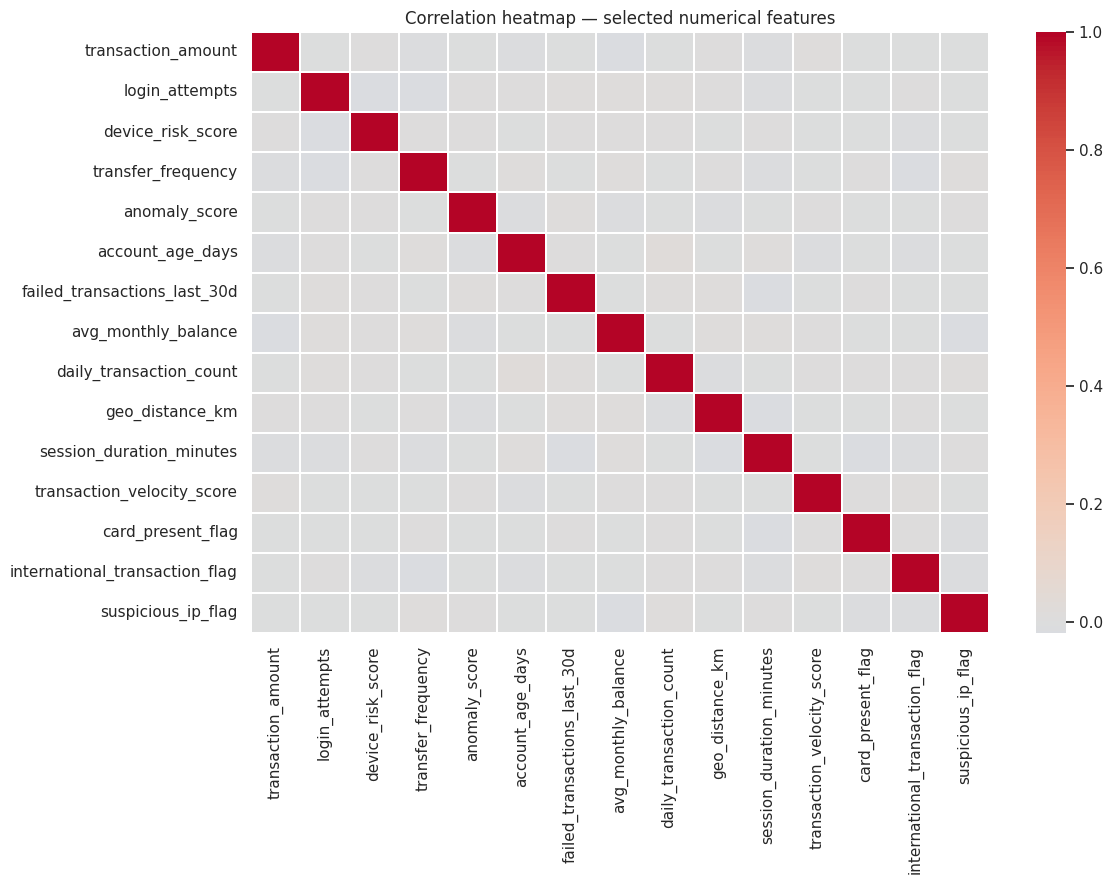

In [95]:
corr_cols = [c for c in numerical_cols if df[c].nunique(dropna=True) > 1][:25]
if len(corr_cols) >= 2:
    corr_matrix = df[corr_cols].corr(numeric_only=True)
    plt.figure(figsize=(12, 9))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, linewidths=0.2)
    plt.title("Correlation heatmap — selected numerical features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough varying numeric features for a correlation heatmap.")

## 8. Data preprocessing and feature engineering plan

This section creates a **working copy** only.

In [96]:
# Start from the raw DataFrame so earlier EDA remains reproducible.
eda_clean = df.copy()

# Normalize whitespace in string columns and treat blank strings as missing.
for col in eda_clean.select_dtypes(include=["object", "string"]).columns:
    eda_clean[col] = eda_clean[col].astype("string").str.strip()
    eda_clean[col] = eda_clean[col].replace("", pd.NA)

# Remove exact duplicate records in this working copy only.
before_rows = len(eda_clean)
eda_clean = eda_clean.drop_duplicates().copy()
print(f"Exact duplicate rows removed from working copy: {before_rows - len(eda_clean):,}")

# Add calendar features from parsed temporal columns; keep the original date column for auditability.
engineered_cols = []
for col in temporal_cols:
    if col in eda_clean.columns and pd.api.types.is_datetime64_any_dtype(eda_clean[col]):
        prefix = str(col).lower().replace(" ", "_")
        eda_clean[f"{prefix}_year"] = eda_clean[col].dt.year
        eda_clean[f"{prefix}_month"] = eda_clean[col].dt.month
        eda_clean[f"{prefix}_dayofweek"] = eda_clean[col].dt.dayofweek
        eda_clean[f"{prefix}_hour"] = eda_clean[col].dt.hour
        engineered_cols.extend([
            f"{prefix}_year", f"{prefix}_month",
            f"{prefix}_dayofweek", f"{prefix}_hour"
        ])

# Exclude target, identifier-like fields, and raw temporal columns from the preliminary predictor list.
excluded_cols = set(identifier_cols) | set(temporal_cols)
if TARGET is not None:
    excluded_cols.add(TARGET)

preliminary_features = [c for c in eda_clean.columns if c not in excluded_cols]
print(f"Working dataset shape after conservative cleaning: {eda_clean.shape}")
print(f"Preliminary predictor count (before modeling-specific preprocessing): {len(preliminary_features)}")
print("Engineered temporal features:", engineered_cols)

# Review remaining missingness in the working copy.
clean_missing = pd.DataFrame({
    "missing_count": eda_clean.isna().sum(),
    "missing_percent": eda_clean.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)
display(clean_missing[clean_missing["missing_count"] > 0].round(2))

Exact duplicate rows removed from working copy: 0
Working dataset shape after conservative cleaning: (10000, 24)
Preliminary predictor count (before modeling-specific preprocessing): 21
Engineered temporal features: ['transaction_time_hour_year', 'transaction_time_hour_month', 'transaction_time_hour_dayofweek', 'transaction_time_hour_hour']


,missing_count,missing_percent


## 9. EDA findings summary


In [98]:
print("# EDA SUMMARY")
print("=" * 60)
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]:,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
print(f"Columns with missing values: {int((df.isna().sum() > 0).sum())}")
print(f"Identifier candidates: {identifier_cols}")
print(f"Temporal columns: {temporal_cols}")
print(f"Numerical predictor candidates: {len(numerical_cols)}")
print(f"Categorical predictor candidates: {len(categorical_cols)}")
print(f"Target: {TARGET}")

if TARGET is not None and TARGET in df.columns:
    print("\nTarget distribution (%):")
    display((df[TARGET].value_counts(normalize=True, dropna=False) * 100)
            .rename("percent").to_frame().round(3))

if not missing_summary.empty:
    print("\nTop columns by missing percentage:")
    display(missing_summary.head(10).round(2))

if not outlier_summary.empty:
    print("\nTop numerical columns by IQR outlier percentage:")
    display(outlier_summary[["column", "outlier_count", "outlier_percent"]].head(10).round(2))

# EDA SUMMARY
Rows: 10,000
Columns: 20
Exact duplicate rows: 0
Columns with missing values: 0
Identifier candidates: ['transaction_id']
Temporal columns: ['transaction_time_hour']
Numerical predictor candidates: 15
Categorical predictor candidates: 3
Target: fraud_flag

Target distribution (%):


,percent
fraud_flag,
False,87.49
True,12.51



Top columns by missing percentage:


,missing_count,missing_percent
transaction_id,0,0.0
transaction_amount,0,0.0
login_attempts,0,0.0
device_risk_score,0,0.0
transfer_frequency,0,0.0
anomaly_score,0,0.0
account_age_days,0,0.0
transaction_time_hour,0,0.0
failed_transactions_last_30d,0,0.0
avg_monthly_balance,0,0.0



Top numerical columns by IQR outlier percentage:


,column,outlier_count,outlier_percent
4,anomaly_score,162,1.62
1,login_attempts,0,0.00
0,transaction_amount,0,0.00
2,device_risk_score,0,0.00
3,transfer_frequency,0,0.00
5,account_age_days,0,0.00
6,failed_transactions_last_30d,0,0.00
7,avg_monthly_balance,0,0.00
8,daily_transaction_count,0,0.00
9,geo_distance_km,0,0.00
